In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kaivalyya/credit-card-fraud-detection/card_transdata.csv


In [2]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    recall_score, precision_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/datasets/kaivalyya/credit-card-fraud-detection/card_transdata.csv')

In [4]:
df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


In [6]:
df.sample(5)

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
762054,103.888195,0.575184,3.265830,1.0,1.0,0.0,1.0,0.0
827613,37.954958,12.179117,1.833383,1.0,1.0,0.0,1.0,0.0
63816,2.169491,0.300993,0.460818,1.0,1.0,0.0,1.0,0.0
641348,1.243446,0.100961,4.327900,0.0,0.0,0.0,1.0,1.0
752137,97.877443,0.270158,2.023026,1.0,0.0,0.0,0.0,0.0


In [7]:
X = df.drop(columns=["fraud"])
y = df["fraud"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 10.44


In [9]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,   
    eval_metric="aucpr",                 
    random_state=42,
    n_jobs=-1,
    device="cpu"         
)

fraud_model = model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

[0]	validation_0-aucpr:0.44147
[50]	validation_0-aucpr:0.99948
[100]	validation_0-aucpr:0.99972
[150]	validation_0-aucpr:0.99972
[200]	validation_0-aucpr:0.99972
[250]	validation_0-aucpr:0.99972
[299]	validation_0-aucpr:0.99971


In [10]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

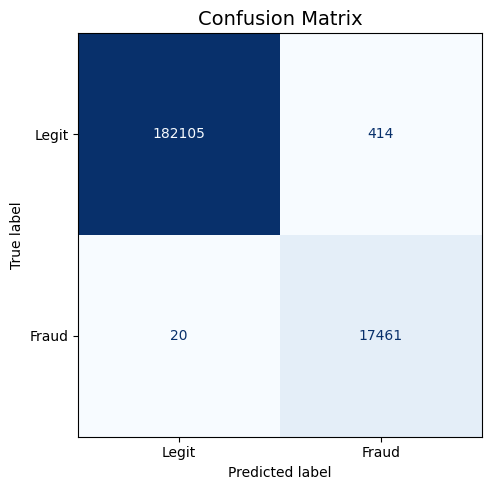

In [11]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legit", "Fraud"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [12]:
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
roc_auc   = roc_auc_score(y_test, y_proba)
print("\n── Classification Report ──────────────────────────")
print(classification_report(y_test, y_pred, target_names=["Legit", "Fraud"], digits=4))
print("── Individual Metrics ─────────────────────────────")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")


── Classification Report ──────────────────────────
              precision    recall  f1-score   support

       Legit     0.9999    0.9977    0.9988    182519
       Fraud     0.9768    0.9989    0.9877     17481

    accuracy                         0.9978    200000
   macro avg     0.9884    0.9983    0.9933    200000
weighted avg     0.9979    0.9978    0.9978    200000

── Individual Metrics ─────────────────────────────
Precision : 0.9768
Recall    : 0.9989
F1 Score  : 0.9877
ROC-AUC   : 1.0000


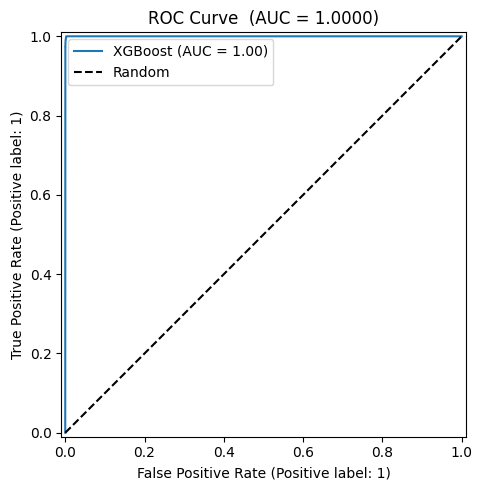

In [13]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax, name="XGBoost")
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_title(f"ROC Curve  (AUC = {roc_auc:.4f})")
ax.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

In [14]:
y_train_pred  = model.predict(X_train)
y_train_proba = model.predict_proba(X_train)[:, 1]
metrics = {
    "Precision": (precision_score(y_train, y_train_pred), precision_score(y_test, y_pred)),
    "Recall":    (recall_score(y_train, y_train_pred),    recall_score(y_test, y_pred)),
    "F1 Score":  (f1_score(y_train, y_train_pred),        f1_score(y_test, y_pred)),
    "ROC-AUC":   (roc_auc_score(y_train, y_train_proba),  roc_auc_score(y_test, y_proba)),
}
print(f"{'Metric':<12} {'Train':>8} {'Test':>8} {'Gap':>8}")
print("-" * 40)
for name, (train_val, test_val) in metrics.items():
    gap = train_val - test_val
    flag = " ⚠️" if abs(gap) > 0.05 else " ✅"
    print(f"{name:<12} {train_val:>8.4f} {test_val:>8.4f} {gap:>+8.4f}{flag}")

Metric          Train     Test      Gap
----------------------------------------
Precision      0.9797   0.9768  +0.0029 ✅
Recall         1.0000   0.9989  +0.0011 ✅
F1 Score       0.9898   0.9877  +0.0020 ✅
ROC-AUC        1.0000   1.0000  +0.0000 ✅


In [15]:
!pip install cloudpickle

In [16]:
import cloudpickle
import numpy as np
import pandas as pd
from dataclasses import dataclass


FEATURE_NAMES = [
    "distance_from_home",
    "distance_from_last_transaction",
    "ratio_to_median_purchase_price",
    "repeat_retailer",
    "used_chip",
    "used_pin_number",
    "online_order",
]
BINARY_FEATURES = {"repeat_retailer", "used_chip", "used_pin_number", "online_order"}


@dataclass
class FraudPrediction:
    label: int
    label_text: str
    fraud_probability: float
    legit_probability: float
    confidence: str
    input_used: dict


class FraudDetector:

    def __init__(self, model):
        self.model = model
        self.feature_names = FEATURE_NAMES

    def _validate(self, data: dict) -> pd.DataFrame:
        errors = []
        missing = [f for f in FEATURE_NAMES if f not in data]
        if missing:
            errors.append(f"Missing features: {missing}")
        for feat, val in data.items():
            if feat not in FEATURE_NAMES:
                continue
            if not isinstance(val, (int, float)):
                errors.append(f"'{feat}' must be numeric")
                continue
            if np.isnan(val) or np.isinf(val):
                errors.append(f"'{feat}' is NaN/Inf")
                continue
            if feat in BINARY_FEATURES and val not in (0, 1, 0.0, 1.0):
                errors.append(f"'{feat}' must be 0 or 1, got {val}")
            if feat not in BINARY_FEATURES and val < 0:
                errors.append(f"'{feat}' must be >= 0, got {val}")
        if errors:
            raise ValueError("Validation failed:\n  " + "\n  ".join(errors))
        return pd.DataFrame([data])[FEATURE_NAMES]

    @staticmethod
    def _confidence(prob: float) -> str:
        if prob >= 0.80 or prob <= 0.20: return "High"
        if prob >= 0.60 or prob <= 0.40: return "Medium"
        return "Low"

    def predict(self, data: dict) -> FraudPrediction:
        X = self._validate(data)
        proba = self.model.predict_proba(X)[0]
        label = int(np.argmax(proba))
        return FraudPrediction(
            label=label,
            label_text="Fraud" if label == 1 else "Legit",
            fraud_probability=round(float(proba[1]), 4),
            legit_probability=round(float(proba[0]), 4),
            confidence=self._confidence(proba[1]),
            input_used=data,
        )


detector = FraudDetector(fraud_model)   # 'model' = your trained XGBClassifier

with open("fraud_detector_cpu.pkl", "wb") as f:
    cloudpickle.dump(detector, f)

print("Saved ✅")


with open("fraud_detector_cpu.pkl", "rb") as f:
    loaded_detector = cloudpickle.load(f)

result = loaded_detector.predict({
    "distance_from_home": 23.0,
    "distance_from_last_transaction": 6.1,
    "ratio_to_median_purchase_price": 0.42,
    "repeat_retailer": 1.0,
    "used_chip": 0.0,
    "used_pin_number": 0.0,
    "online_order": 1.0,
})
print(result)

Saved ✅
FraudPrediction(label=0, label_text='Legit', fraud_probability=0.0, legit_probability=1.0, confidence='High', input_used={'distance_from_home': 23.0, 'distance_from_last_transaction': 6.1, 'ratio_to_median_purchase_price': 0.42, 'repeat_retailer': 1.0, 'used_chip': 0.0, 'used_pin_number': 0.0, 'online_order': 1.0})


In [17]:
import os

print(os.path.abspath("fraud_detector.pkl"))

size = os.path.getsize("fraud_detector.pkl")
print(f"Size: {size / 1024:.1f} KB")

/kaggle/working/fraud_detector.pkl


FileNotFoundError: [Errno 2] No such file or directory: 'fraud_detector.pkl'

In [18]:
with open("/kaggle/working/fraud_detector_cpu.pkl", "wb") as f:
    cloudpickle.dump(detector, f)
print("Done — check Output panel on the right →")

Done — check Output panel on the right →


In [19]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.2.0


In [20]:
fraud_model.save_model("fraud_model.json")

print("XGBoost model saved ✅")

XGBoost model saved ✅
